# **Etape 1 : Data Collection**

In [1]:
import pandas as pd
import csv

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        

/kaggle/input/datasets/oussamaberredjem/fake-news-classification/evaluation.csv


# 1.1 Import Dataset

In [3]:
df = pd.read_csv(
        "/kaggle/input/datasets/oussamaberredjem/fake-news-classification/evaluation.csv",
        sep=';'
    )

df = df.drop(columns=['Unnamed: 0','title'])
df.head()


,text,label
0,WASHINGTON (Reuters) - Democratic U.S. preside...,1
1,MOSCOW (Reuters) - A proposal to convene a con...,1
2,"In a baffling fit of rage, an Oregon State Pol...",0
3,The last thing any politician running for the ...,0
4,This is too good to miss! Mr. Teleprompter did...,0


# **Etape 2 : Text Preprocessing**

* normalize
* remove stopwords
* Tokenize
* stem/lemmatize

# 2.1: Nettoyage de Text

In [4]:
import re
import nltk
from nltk.corpus import stopwords

mot_vide = set(stopwords.words('english'))

print(mot_vide)

{"should've", 'in', 'ain', "he'll", 'then', 'this', 'wasn', 'on', 'do', "doesn't", 's', 'from', 'is', 'had', "shouldn't", "we'd", 'or', "we've", 'hasn', 'aren', 'we', 'you', 'have', 'during', "i'm", 'am', "that'll", 'mustn', 'with', 'against', "i'll", 'than', 'o', 'these', 'by', 'didn', "wouldn't", 'all', "didn't", 'when', "we're", "won't", 'shouldn', 'shan', "it'd", "needn't", 'both', 'once', "she'll", 'him', 'whom', "couldn't", 'does', 'other', 'herself', 'some', 'nor', 'how', 'who', 'any', 'our', "you're", 'were', 'few', 'what', 're', 'me', "you've", 'most', 'needn', "we'll", "shan't", 'couldn', 'isn', 'above', 'will', 'only', 'his', 'here', 'd', 'that', "he'd", "he's", 've', 'its', "it'll", "mightn't", 'the', 'm', 'before', "they'll", "they've", "don't", 'into', "you'll", 'don', 'haven', 'having', 'no', 'to', "wasn't", 'over', 'more', 'which', 'an', "they'd", 'until', 'y', 'your', 'hadn', 'again', 'same', 'her', 'very', 'won', 'just', "they're", 'doesn', 'about', 'their', 'of', 'ea

In [5]:
def remove_symboles(text):
    if isinstance(text, str):
        text = text.lower()
        text = re.sub(r'\$(\d+(?:\.\d+)?(?: billion| million)?)', r'\1 dollar', text)
        text = re.sub(r'[^\w\s]', '', text)
        text = re.sub(r'\d+', '', text)
        text = re.sub(r'\s+', ' ', text).strip()
    return text

def remove_stopwords(text):
    if isinstance(text, str):
        words = text.split()
        words = [word for word in words if word not in mot_vide and len(word) > 1]
        return ' '.join(words)
    return text

print("Application du nettoyage...")
text = remove_symboles(df['text'][0])
text = remove_stopwords(text)

print("\nApercu des resultats:")
print(text)

Application du nettoyage...

Apercu des resultats:
washington reuters democratic us presidential hopeful bernie sanders brought firebrand rhetoric back floor senate tuesday condemn white housebacked bill puerto ricos financial crisis colonialism worst sanders selfdescribed democratic socialist turned unlikely presidential bid political movement combat inequality warned legislation due crucial senate vote wednesday would subject puerto rico republican trickledown economics favor vulture capitalists expense islands increasingly impoverished population aide said first time sanders spoken senate since december sound like kind morality passed united states senate sanders fumed eightminute appearance support hourslong speech democratic senator robert menendez new jersey opposes bill vermont senator used appearance rail details legislation would put much puerto ricos management hands sevenmember oversight board require island pay million dollar five years boards administration costs even cuts

# **2.2 : Stemming**

In [6]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.model_selection import train_test_split
import ssl
import warnings
import pickle

In [7]:
stemmer = PorterStemmer()

def apply_stemming(text):
    if isinstance(text, str):
        words = text.split()
        stemmed_words = [stemmer.stem(word) for word in words]
        return ' '.join(stemmed_words)
    return text

text = apply_stemming(df['text'][0])


print("Exemple de texte après stemming:")
print(f"Stemmed: {text}...")
        

Exemple de texte après stemming:
Stemmed: washington (reuters) - democrat u.s. presidenti hope berni sander brought hi firebrand rhetor back to the floor of the senat on tuesday to condemn a white house-back bill on puerto rico’ financi crisi as “coloni at it worst.” sanders, a self-describ democrat socialist who turn an unlik presidenti bid into a polit movement to combat inequality, warn that legisl due for a crucial senat vote on wednesday would subject puerto rico to republican trickle-down econom and favor “vultur capitalists” at the expens of the island’ increasingli impoverish population. an aid said it wa the first time sander ha spoken in the senat sinc december. “doe that sound like the kind of moral that should be pass here in the unit state senate?” sander fume dure an eight-minut appear to support an hours-long speech by democrat senat robert menendez of new jersey, who oppos the bill. the vermont senat use hi appear to rail against detail of the legislation, which would p

# **2.3: LEMMATISATION**

In [8]:
lemmatizer = WordNetLemmatizer()

def apply_lemmatization(text):
    if isinstance(text, str):
        words = text.split()
        lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
        return ' '.join(lemmatized_words)
    return text

text = apply_lemmatization(df['text'][0])


print("Exemple de texte apres lemmatisation:")
print(f"Lemmatized: {text}...")

Exemple de texte apres lemmatisation:
Lemmatized: WASHINGTON (Reuters) - Democratic U.S. presidential hopeful Bernie Sanders brought his firebrand rhetoric back to the floor of the Senate on Tuesday to condemn a White House-backed bill on Puerto Rico’s financial crisis a “colonialism at it worst.” Sanders, a self-described democratic socialist who turned an unlikely presidential bid into a political movement to combat inequality, warned that legislation due for a crucial Senate vote on Wednesday would subject Puerto Rico to Republican trickle-down economics and favor “vulture capitalists” at the expense of the island’s increasingly impoverished population. An aide said it wa the first time Sanders ha spoken in the Senate since December. “Does that sound like the kind of morality that should be passed here in the United States Senate?” Sanders fumed during an eight-minute appearance to support an hours-long speech by Democratic Senator Robert Menendez of New Jersey, who opposes the bill

# **Preprocessing Call**

In [9]:
import numpy as np


def preprocess(text):
    text = str(text)
    text = remove_symboles(text)
    text = remove_stopwords(text)
    text = apply_stemming(text)
    text = apply_lemmatization(text)
    return text


def preprocess_array(texts):
    return np.array([preprocess(text) for text in texts])

df['text_clean'] = df['text'].apply(preprocess)

print(df['text'][2])
print(df['text_clean'][2])

In a baffling fit of rage, an Oregon State Police officer has been convicted of ramming his car into a stopped motorcyclist then kicking the dazed man so hard in the chest that he would need a metal plate and screws to repair his shattered collarbone and ribs. What State Police Captain Rob Edwards didn t know was that his department have installed a functioning dashboard camera. It captured the entire shocking scene.The 2012 incident with a chase that the victim says he didn t know was happening. The first he learned of Edwards  presence was when the cop was running directly into the back of his motorcycle, spilling the man from his bike. The man gets up with his hands raised only to find Edwards rushing at him with his pistol held sideways, probably imitating something he saw in a movie. The biker, identified as Justin Wilkens, barely had time to say  What did I do?  before Edwards kicked him square in the chest with such force that Wilkens would later learn he broke his collarbone an

# **2.4: SPLIT TRAIN/TEST**

In [10]:
METHOD = 'text_clean'

X = df['text_clean']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Taille entrainement: {len(X_train)} echantillons")
print(f"Taille test: {len(X_test)} echantillons\n")

Taille entrainement: 6493 echantillons
Taille test: 1624 echantillons



# **Etape3 : Feature Engineering (TF-IDF avec n-grams)** 

# **3.1. TF-IDF Vectorization**

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("Création de Vectoriseur TF-IDF:\n")

tfidf = TfidfVectorizer(
    max_features=5000,
)

print("Le vectoriseur TF-IDF a été bien initialisé avec la configuration suivante :")
print(tfidf)

Création de Vectoriseur TF-IDF:

Le vectoriseur TF-IDF a été bien initialisé avec la configuration suivante :
TfidfVectorizer(max_features=5000)


# **3.4. Pipeline**

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# **3.4.1 Pipeline SVM**

In [13]:
from sklearn.svm import SVC


pipeline = Pipeline([
    ('tfidf', tfidf),
    ('svm', SVC())
])



# **3.4.2 Pipeline Naive Bayes**

In [14]:
from sklearn.naive_bayes import MultinomialNB

pipeline_nb = Pipeline([
    ('tfidf', tfidf),
    ('nb', MultinomialNB())
])

# **3.4.1 Pipeline Logistique Regression**

In [15]:
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline([
    ('tfidf', tfidf),
    ('lr', LogisticRegression(max_iter=1000))
])

# **Etape 4 : Optimisation des hyperparamètres**

In [16]:

from sklearn.model_selection import GridSearchCV

# **4.1. SVM Grid Search Optimisation**

In [17]:
param_grid = {
    'tfidf__ngram_range': [(1,2)],
    'tfidf__max_df': [0.8, 1.0],
    'tfidf__min_df': [1, 5],
    'svm__C': [0.1, 1, 10],
    'svm__kernel': ['linear', 'rbf']
}

grid = GridSearchCV(pipeline, param_grid, cv=3, n_jobs=-1,return_train_score=True)
grid.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(max_features=5000)),
                                       ('svm', SVC())]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10],
                         'svm__kernel': ['linear', 'rbf'],
                         'tfidf__max_df': [0.8, 1.0], 'tfidf__min_df': [1, 5],
                         'tfidf__ngram_range': [(1, 2)]},
             return_train_score=True)

# **4.2. SVM Grid Search Best Params**

In [18]:
print("Best parameters found:")
print(grid.best_params_)

Best parameters found:
{'svm__C': 1, 'svm__kernel': 'linear', 'tfidf__max_df': 0.8, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}


# **4.3. Naive Bayes Grid Search Optimisation**

In [19]:
from sklearn.model_selection import GridSearchCV


param_grid_nb = {
    'tfidf__max_features':[5000],
    'tfidf__max_df': [0.7, 0.8, 0.9],
    'tfidf__min_df': [1, 5, 10],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'nb__alpha': [0.1,0.3, 1]
}

grid_nb = GridSearchCV(pipeline_nb, param_grid_nb, cv=5, n_jobs=-1,return_train_score=True)
grid_nb.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(max_features=5000)),
                                       ('nb', MultinomialNB())]),
             n_jobs=-1,
             param_grid={'nb__alpha': [0.1, 0.3, 1],
                         'tfidf__max_df': [0.7, 0.8, 0.9],
                         'tfidf__max_features': [5000],
                         'tfidf__min_df': [1, 5, 10],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             return_train_score=True)

# **4.4. Naive Bayes Grid Search Best Params**

In [20]:
print("Best parameters found:")
print(grid_nb.best_params_)

Best parameters found:
{'nb__alpha': 0.1, 'tfidf__max_df': 0.8, 'tfidf__max_features': 5000, 'tfidf__min_df': 10, 'tfidf__ngram_range': (1, 2)}


# **4.5. Logistic Regression Grid Search Optimisation**

In [21]:
param_grid_lr = {
    'tfidf__max_df': [0.7, 0.8, 0.9],
    'tfidf__min_df': [1, 5, 10],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'lr__C': [0.1, 1, 10],
    'lr__solver': ['liblinear']
}

grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, n_jobs=-1,return_train_score=True)


grid_lr.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(max_features=5000)),
                                       ('lr',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'lr__C': [0.1, 1, 10], 'lr__solver': ['liblinear'],
                         'tfidf__max_df': [0.7, 0.8, 0.9],
                         'tfidf__min_df': [1, 5, 10],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             return_train_score=True)

# **4.6. Logistique Regression Grid Search Best Params**

In [22]:
print("Best parameters (Logistic Regression):")
print(grid_lr.best_params_)

Best parameters (Logistic Regression):
{'lr__C': 10, 'lr__solver': 'liblinear', 'tfidf__max_df': 0.8, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


# **Etape 6 : Analyse biais-variance.**

In [23]:
import matplotlib.pyplot as plt

def bias_variance_analysis(grid):
    results = grid.cv_results_
    best_idx = grid.best_index_
    best_train = results['mean_train_score'][best_idx]
    best_val = results['mean_test_score'][best_idx]

    print("Train:", round(best_train, 3))
    print("Validation:", round(best_val, 3))

    if best_train - best_val > 0.1:
        print("➡️ Overfitting (High Variance)")
    elif best_train < 0.75 and best_val < 0.75:
        print("➡️ Underfitting (High Bias)")
    else:
        print("➡️ Good Balance")

    plt.plot(results['mean_train_score'], label="Train")
    plt.plot(results['mean_test_score'], label="Validation")
    plt.legend()
    plt.title("Bias-Variance")
    plt.show()
    
    return best_train, best_val

In [24]:
results = {}
bests = {}

# **6.1 SVM Analyse biais-variance.**

Train: 0.988
Validation: 0.966
➡️ Good Balance


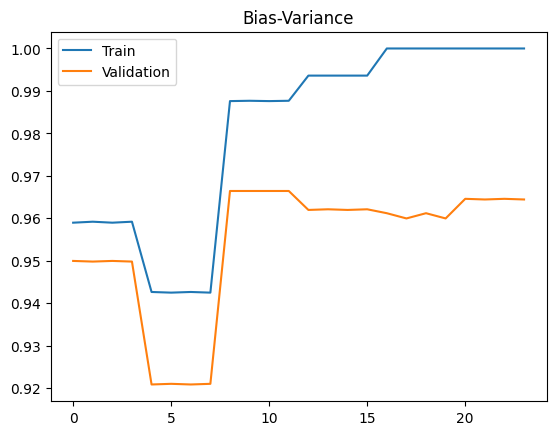

In [25]:
results['svm'] = bias_variance_analysis(grid)

# **6.3 Naive Bayes Analyse biais-variance.**

Train: 0.938
Validation: 0.926
➡️ Good Balance


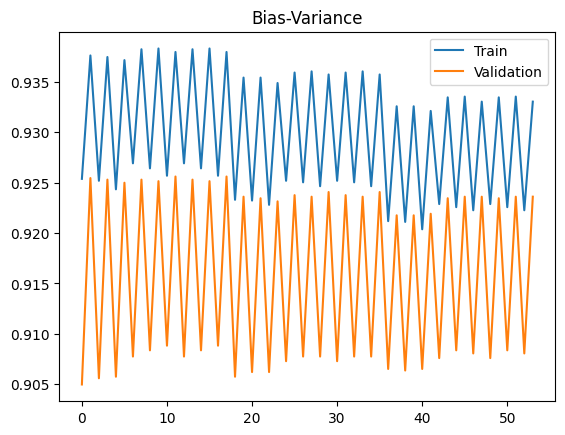

In [26]:
results['nb'] = bias_variance_analysis(grid_nb)

# **6.3 Logistique Regression Analyse biais-variance.**

Train: 0.996
Validation: 0.965
➡️ Good Balance


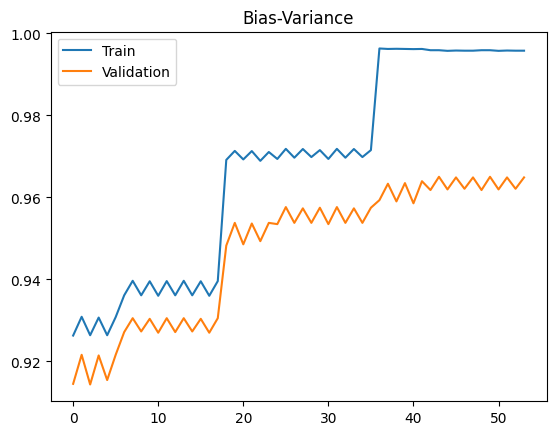

In [27]:
results['lr'] = bias_variance_analysis(grid_lr)

# **6.4. Best Bias-Varience Model**

In [28]:
best_model = max(results.items(), key=lambda x: x[1][1])
bests['bias-variance'] = (best_model[0],best_model[1][1])
print(f"\n🏆 Best Bias-Variance model: {best_model[0]} with validation score: {best_model[1][1]:.4f}")


🏆 Best Bias-Variance model: svm with validation score: 0.9664


# **Etape 7 : Comparaison statistique des modèles**

In [29]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy.stats import ttest_rel,f_oneway

# **7.1. Get Best Models**

In [30]:
best_lr = grid_lr.best_estimator_
best_nb = grid_nb.best_estimator_
best_svm = grid.best_estimator_

# **7.2. Fold Cross Validation**

In [31]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# **7.3. Get Scores**

In [32]:
lr_scores = cross_val_score(best_lr, X_train, y_train, cv=cv, scoring='accuracy')
nb_scores = cross_val_score(best_nb, X_train, y_train, cv=cv, scoring='accuracy')
svm_scores = cross_val_score(best_svm, X_train, y_train, cv=cv, scoring='accuracy')

print(f"Logistique Regression :      {lr_scores.mean():.4f} ± {lr_scores.std():.4f}")
print(f"Naive Bayes: {nb_scores.mean():.4f} ± {nb_scores.std():.4f}")
print(f"SVM: {svm_scores.mean():.4f} ± {svm_scores.std():.4f}")

Logistique Regression :      0.9663 ± 0.0070
Naive Bayes: 0.9279 ± 0.0138
SVM: 0.9684 ± 0.0062


# **7.4. Statistical test & Comparaisons**

In [33]:
f_stat, p_value_anova = f_oneway(lr_scores, nb_scores, svm_scores)
print(f"\np-value: {p_value_anova:.4f}")

if p_value_anova < 0.05:
    print("✅ Significant difference among models")
else:
    print("❌ No significant difference among models")

print("\n--- Pairwise Comparisons ---")
t_stat, p_value_lr_nb = ttest_rel(lr_scores, nb_scores)
print(f"Logistic Regression vs Naive Bayes: p = {p_value_lr_nb:.4f}")

t_stat, p_value_lr_svm = ttest_rel(lr_scores, svm_scores)
print(f"Logistic Regression vs SVM: p = {p_value_lr_svm:.4f}")

t_stat, p_value_nb_svm = ttest_rel(nb_scores, svm_scores)
print(f"Naive Bayes vs SVM: p = {p_value_nb_svm:.4f}")


p-value: 0.0000
✅ Significant difference among models

--- Pairwise Comparisons ---
Logistic Regression vs Naive Bayes: p = 0.0000
Logistic Regression vs SVM: p = 0.0775
Naive Bayes vs SVM: p = 0.0000


# **7.5. Presentation Graphique**

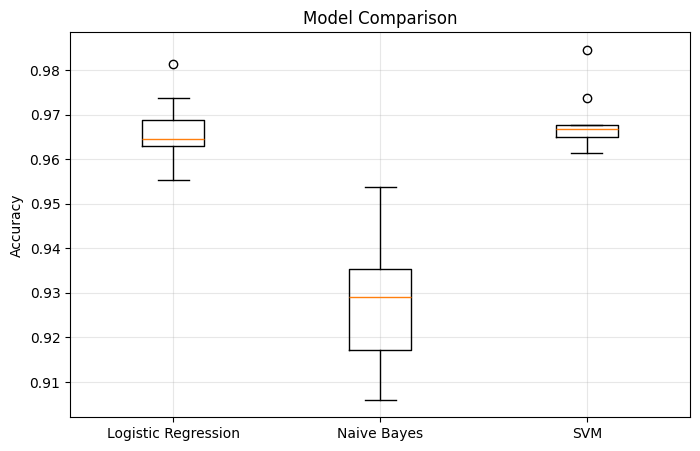

In [34]:
plt.figure(figsize=(8, 5))
plt.boxplot([lr_scores, nb_scores, svm_scores], tick_labels=['Logistic Regression', 'Naive Bayes', 'SVM'])
plt.title('Model Comparison')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)
plt.show()

# **7.6. Find Best Statistique Model**

In [35]:
scores_mean = {
    'Logistic Regression': lr_scores.mean(),
    'Naive Bayes': nb_scores.mean(),
    'SVM': svm_scores.mean()
}
best_model = max(scores_mean, key=scores_mean.get)
bests['statistique'] = (best_model,scores_mean[best_model])

print(f"\n🏆 Best Statistique model: {best_model} with accuracy {scores_mean[best_model]:.4f}")


🏆 Best Statistique model: SVM with accuracy 0.9684


# **Etape 8 : Mesurer le temps d’entrainement**

In [36]:
import time

In [37]:
svm_model = grid.best_estimator_
nb_model = grid_nb.best_estimator_
lr_model = grid_lr.best_estimator_

# **8.1. SVM Temp Mesure**

In [38]:
start_time = time.time()
svm_model.fit(X_train, y_train)
svm_train_time = time.time() - start_time

print(f"SVM training time: {svm_train_time:.2f} sec")

SVM training time: 20.36 sec


# **8.2. Naive Bayes Temp Mesure**

In [39]:
start_time = time.time()
nb_model.fit(X_train, y_train)
nb_train_time = time.time() - start_time

print(f"Naive Bayes training time: {nb_train_time:.2f} sec")

Naive Bayes training time: 4.84 sec


# **8.3. Logistique Regression Temp Mesure**

In [40]:
start_time = time.time()
lr_model.fit(X_train, y_train)
lr_train_time = time.time() - start_time

print(f"Logistique Regression training time: {lr_train_time:.2f} sec")

Logistique Regression training time: 4.90 sec


# **8.4. Comparatif Graphique des temps**

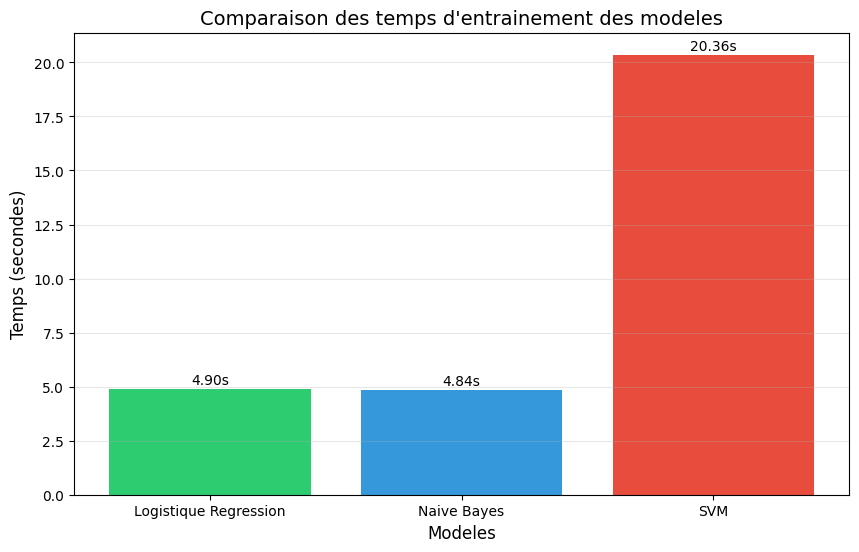

In [41]:
models = ['Logistique Regression', 'Naive Bayes', 'SVM']
train_times = [lr_train_time, nb_train_time, svm_train_time]

plt.figure(figsize=(10, 6))
plt.bar(models, train_times, color=['#2ecc71', '#3498db', '#e74c3c'])


plt.title('Comparaison des temps d\'entrainement des modeles', fontsize=14)
plt.ylabel('Temps (secondes)', fontsize=12)
plt.xlabel('Modeles', fontsize=12)
plt.grid(axis='y', alpha=0.3)

for i, v in enumerate(train_times):
    plt.text(i, v + (max(train_times) * 0.01), f'{v:.2f}s', ha='center', fontsize=10)

plt.show()

# **8.5. Trouver Meilleur Modele**

In [42]:
times_mean = {
    'Logistic Regression': lr_train_time,
    'Naive Bayes': nb_train_time,
    'SVM': svm_train_time
}
best_model = min(times_mean, key=times_mean.get)
bests['time'] = (best_model,times_mean[best_model])

print(f"\n🏆 Best Time model: {best_model} with Time {times_mean[best_model]:.2f}")


🏆 Best Time model: Naive Bayes with Time 4.84


# **8.6. Evalution Reel du Models**

In [43]:
from sklearn.metrics import accuracy_score

# Predictions
y_pred_lr = best_lr.predict(X_test)
y_pred_nb = best_nb.predict(X_test)
y_pred_svm = best_svm.predict(X_test)

# Accuracy
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_nb = accuracy_score(y_test, y_pred_nb)
acc_svm = accuracy_score(y_test, y_pred_svm)

# Print results
print(f"Logistic Regression Accuracy: {acc_lr:.4f}")
print(f"Naive Bayes Accuracy:         {acc_nb:.4f}")
print(f"SVM Accuracy:                 {acc_svm:.4f}")

# Find best model
accuracies = {
    "Logistic Regression": acc_lr,
    "Naive Bayes": acc_nb,
    "SVM": acc_svm
}

best_model_name = max(accuracies, key=accuracies.get)
best_score = accuracies[best_model_name]

print("\n🏆 Best Model:")
print(f"{best_model_name} with accuracy = {best_score:.4f}")

Logistic Regression Accuracy: 0.9637
Naive Bayes Accuracy:         0.9243
SVM Accuracy:                 0.9680

🏆 Best Model:
SVM with accuracy = 0.9680


# **Etape 9 : Interétation des Variables**

In [44]:
!pip install wordcloud -q
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

top_n = 20

# **9.1. Importance des Mots (Linear SVM)**

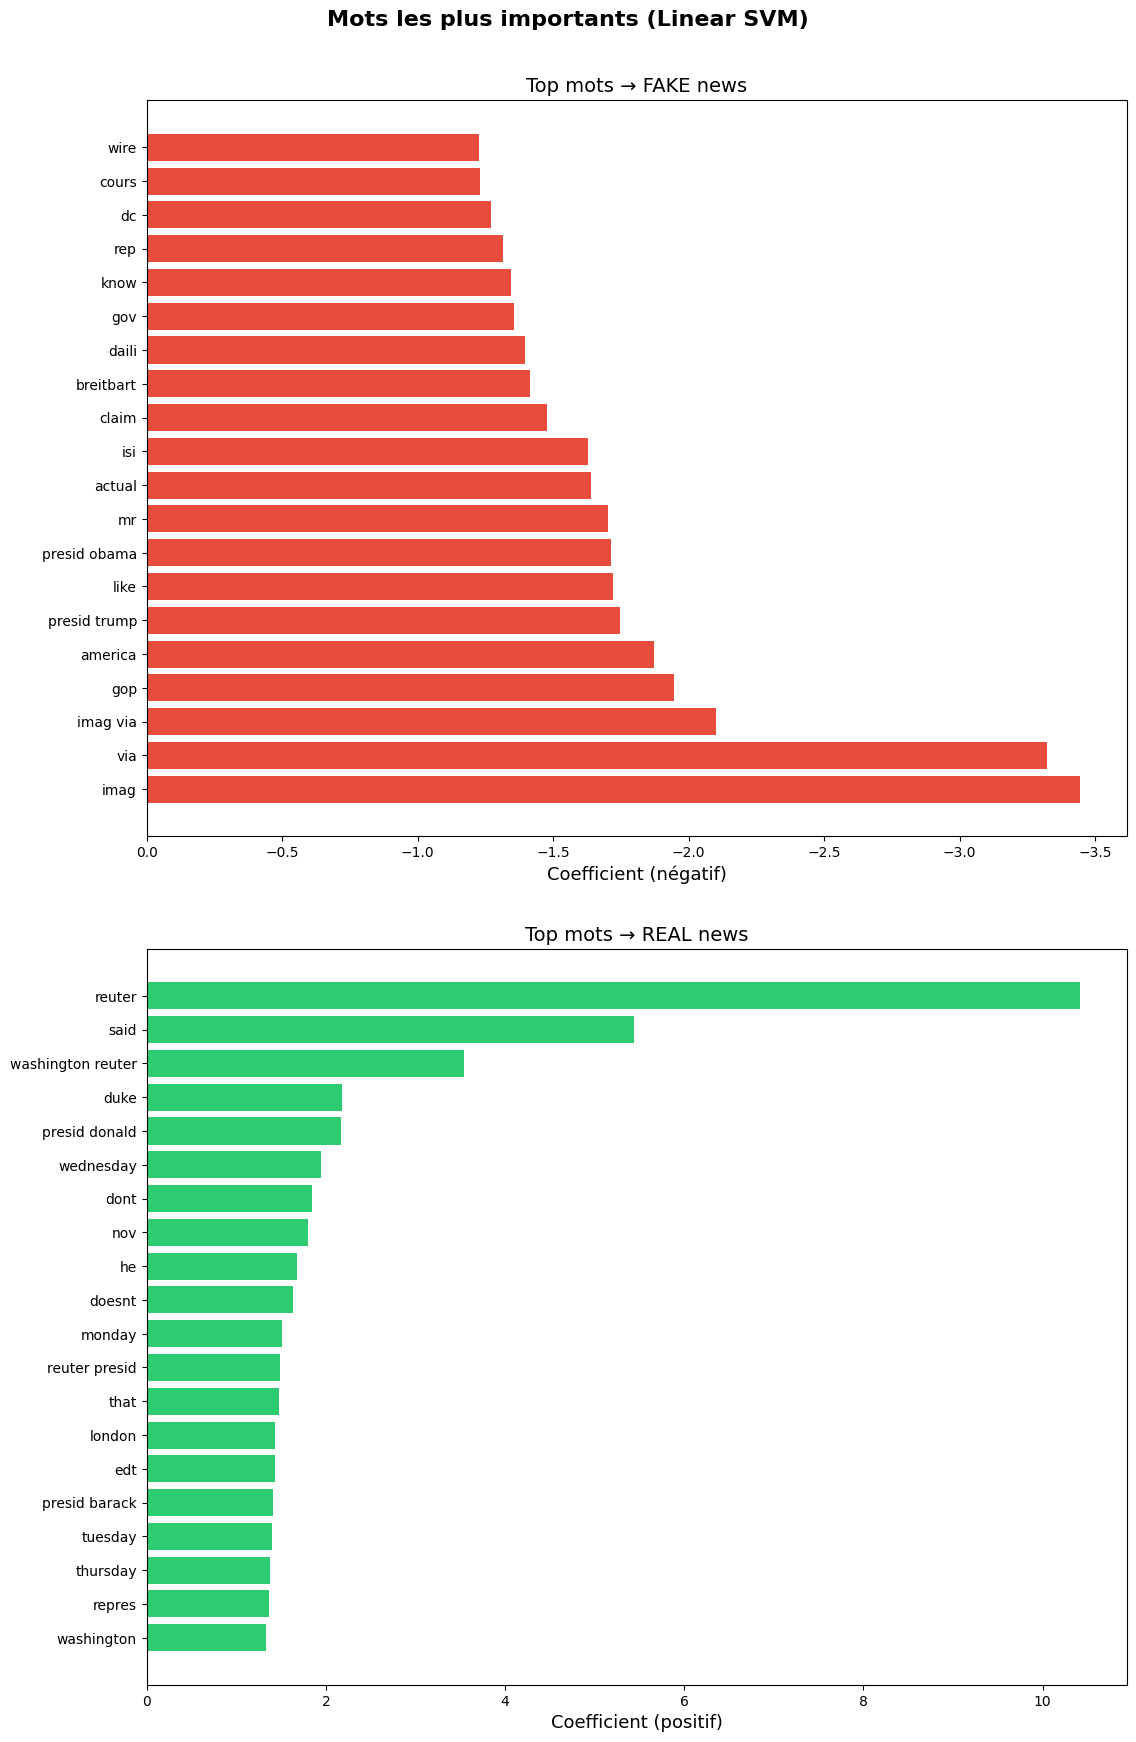

In [45]:
feature_names = svm_model.named_steps['tfidf'].get_feature_names_out()
coefs = svm_model.named_steps['svm'].coef_[0]

if hasattr(svm_model.named_steps['svm'].coef_, 'toarray'):
    coefs = svm_model.named_steps['svm'].coef_.toarray()[0]
else:
    coefs = svm_model.named_steps['svm'].coef_[0]

idx_fake = np.argsort(coefs)[:top_n]
idx_real = np.argsort(coefs)[-top_n:]

fig, axes = plt.subplots(2, 1, figsize=(12, 18))
axes[0].barh(feature_names[idx_fake], coefs[idx_fake], color='#e74c3c')
axes[0].set_title('Top mots → FAKE news', fontsize=14)
axes[0].set_xlabel('Coefficient (négatif)', fontsize=13)
axes[0].invert_xaxis()
axes[1].barh(feature_names[idx_real], coefs[idx_real], color='#2ecc71')
axes[1].set_title('Top mots → REAL news', fontsize=14)
axes[1].set_xlabel('Coefficient (positif)', fontsize=13)

plt.suptitle('Mots les plus importants (Linear SVM)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(pad=3.0)
plt.show()

# **9.2. WordCloud : Fake vs Real**

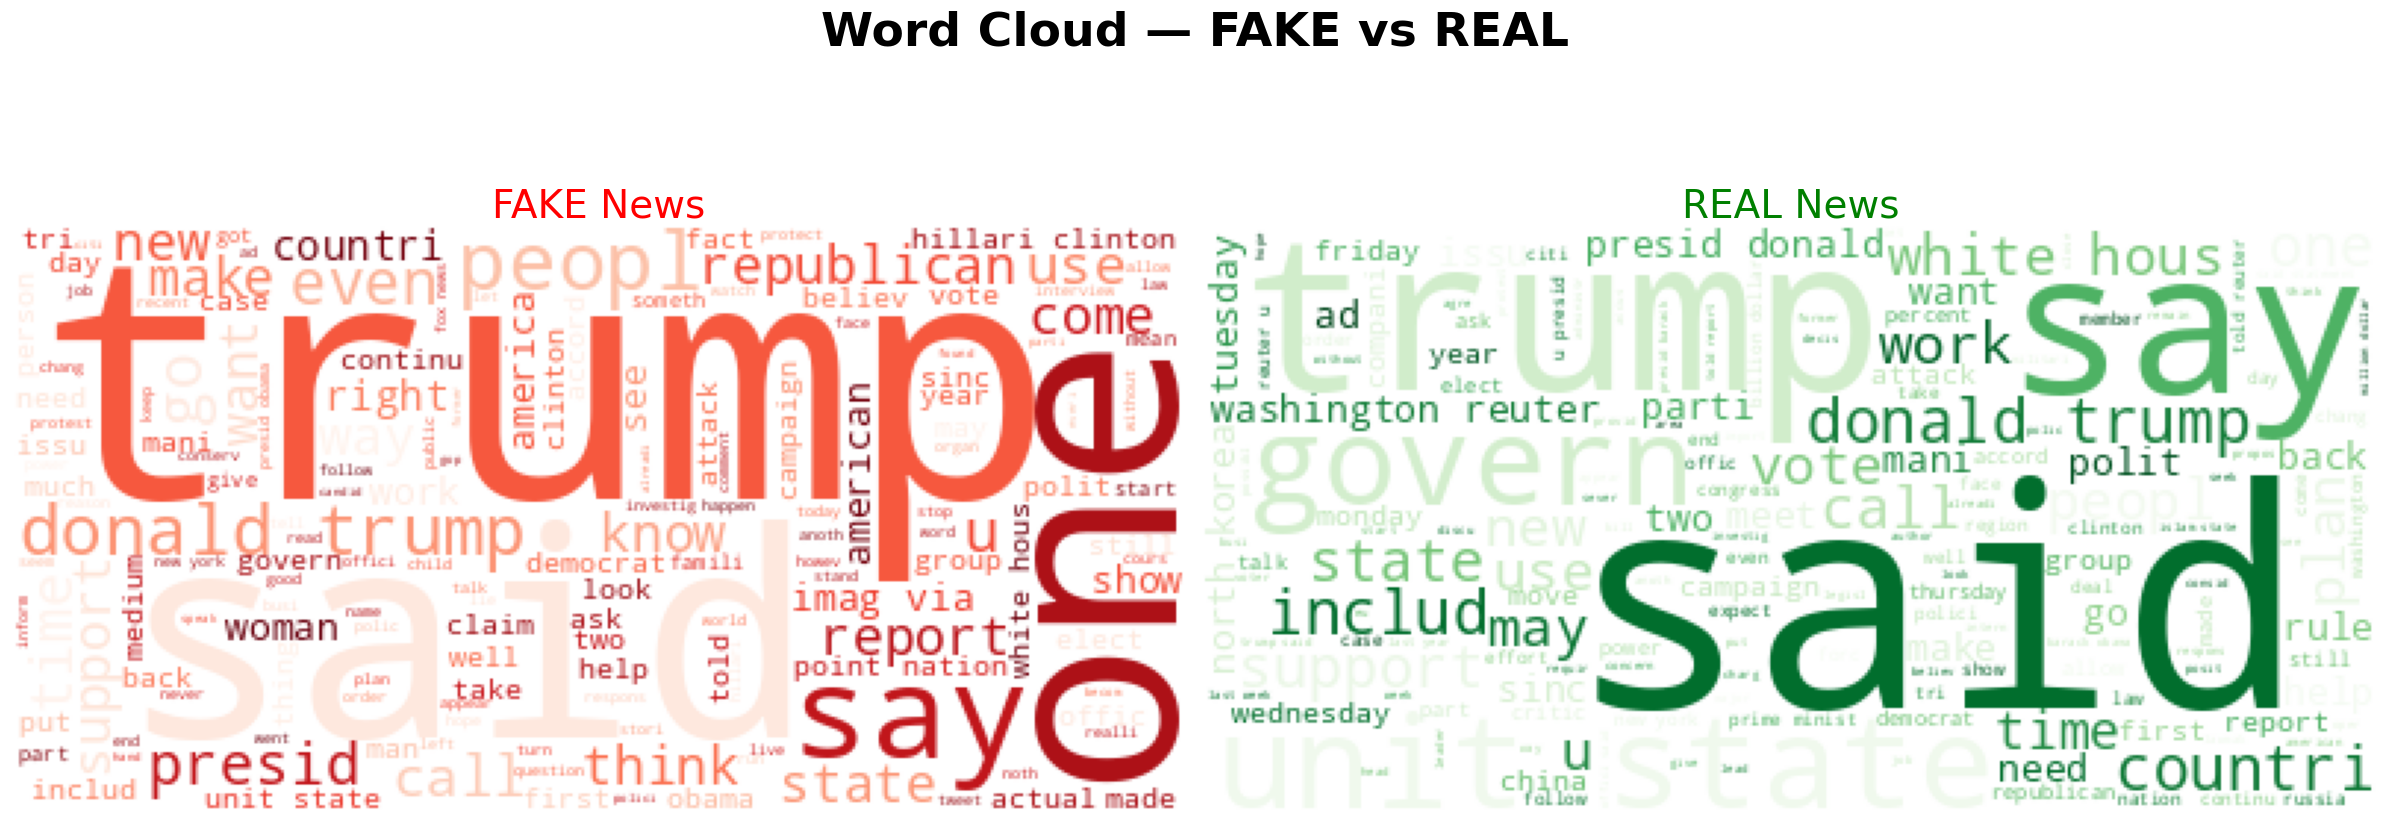

In [46]:
fake_text = ' '.join(df[df['label'] == 0]['text_clean'].astype(str))
real_text = ' '.join(df[df['label'] == 1]['text_clean'].astype(str))

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
axes[0].imshow(WordCloud(colormap='Reds', background_color='white').generate(fake_text))
axes[0].set_title('FAKE News', color='red', fontsize=28)
axes[0].axis('off')
axes[1].imshow(WordCloud(colormap='Greens', background_color='white').generate(real_text))
axes[1].set_title('REAL News', color='green', fontsize=28)
axes[1].axis('off')

plt.suptitle('Word Cloud — FAKE vs REAL', fontsize=34, fontweight='bold')
plt.tight_layout()
plt.show()

# **9.3. Interprétation**

In [47]:
print("""
Dans cette étape, nous avons analysé les coefficients du modèle SVM linéaire, 
qui est notre meilleur modèle avec une accuracy de 96,84%, afin de comprendre 
et de déterminer l'influence des mots sur le processus de classification. 

Nous avons choisi ce modèle car il offre à la fois d'excellentes performances 
et des coefficients directement interprétables, contrairement au SVM avec 
noyau RBF qui agit comme une "boîte noire".

Nous observons que les mots ayant un coefficient négatif sont associés aux 
Fake News, tandis que ceux à coefficient positif sont associés aux Real News. 
Cela signifie que notre modèle utilise des mots spécifiques pour déterminer 
si les informations sont vraies ou fausses. 

Enfin, le WordCloud permet de visualiser les mots les plus fréquents dans 
les deux catégories, ce qui confirme les tendances observées dans les 
coefficients du modèle.  
""")


Dans cette étape, nous avons analysé les coefficients du modèle SVM linéaire, 
qui est notre meilleur modèle avec une accuracy de 96,84%, afin de comprendre 
et de déterminer l'influence des mots sur le processus de classification. 

Nous avons choisi ce modèle car il offre à la fois d'excellentes performances 
et des coefficients directement interprétables, contrairement au SVM avec 
noyau RBF qui agit comme une "boîte noire".

Nous observons que les mots ayant un coefficient négatif sont associés aux 
Fake News, tandis que ceux à coefficient positif sont associés aux Real News. 
Cela signifie que notre modèle utilise des mots spécifiques pour déterminer 
si les informations sont vraies ou fausses. 

Enfin, le WordCloud permet de visualiser les mots les plus fréquents dans 
les deux catégories, ce qui confirme les tendances observées dans les 
coefficients du modèle.  

